# 04 · The winter North Atlantic Oscillation

**Question for this notebook.** Do the two EERIE models produce a realistic winter NAO: the right
pattern, the right strength, and realistic behaviour in time?

**What the NAO is.** The NAO is the leading see-saw of winter sea-level pressure over the North
Atlantic. In a *positive* NAO winter, pressure is lower than usual near Iceland and higher than
usual near the Azores; the westerly winds are stronger and northern Europe is mild and wet.
A *negative* winter is the reverse.

**Data.** Monthly sea-level pressure, 1950–2014, on the North Atlantic box (20–80°N, 90°W–40°E, 1° grid):
ERA5 (reanalysis reference), ICON-ESM-ER r1 and IFS-FESOM2-SR r1.

**Method** (fixed in `docs/methods.md` before any result was produced):
1. Subtract the 1950–2014 mean of each calendar month, giving anomalies.
2. Average December–February into one map per winter. December belongs to the following year's
   winter, so the first complete winter is 1951 and there are **64 winters**, 1951–2014.
3. Weight each grid point by √cos(latitude), so the many small high-latitude cells do not dominate.
4. Take the leading EOF: the single pattern that explains the most winter-to-winter variance.
5. Fix the sign so that positive means low pressure near Iceland and high pressure near the Azores.
6. The NAO index is the strength of that pattern each winter, in standard deviations.

**An important reminder.** A free-running model has its own sequence of winters. The model index is
*not* expected to match the ERA5 index year by year. Patterns, strength and statistics are compared.

**Sections**
1. Setup
2. Findings
3. The NAO pattern
4. The NAO index
5. Cross-checks: a station-style index and a common pattern
6. Behaviour in time: persistence and trend
7. Does the mean-state bias look like the NAO?
8. Does the result depend on the domain?
9. Saved outputs
9. Limitations
10. Open questions

## Background: the terms used in this notebook

If you know these already, skip to section 1.

| Term | What it means here |
|---|---|
| **Anomaly** | The difference from normal. Here: a month's pressure minus the 1950–2014 average for that calendar month. A winter anomaly map shows where pressure was higher or lower than usual that winter. |
| **EOF (empirical orthogonal function)** | A way to find the dominant pattern in a set of maps. The leading EOF is the single map that, made stronger or weaker and flipped in sign from winter to winter, reproduces as much of the winter-to-winter variation as one pattern can. It is the same mathematics as principal component analysis (PCA). |
| **Index (principal component)** | One number per winter saying how strongly, and with which sign, that winter resembled the pattern. This is the NAO index. |
| **Explained variance** | The share of all winter-to-winter variation that the pattern accounts for. For the real NAO this is roughly 40–50% in winter. |
| **SD (standard deviation)** | The typical size of the swings of the index. An index of +1 SD is a moderately positive winter; ±2 SD is rare, about one winter in twenty. |
| **Sign convention** | The mathematics does not decide which way round the pattern is. We fix it: positive = low pressure near Iceland, high pressure near the Azores. |
| **Station-style index** | The traditional NAO definition used long before EOFs: pressure at a southern station (Azores, Lisbon or Gibraltar) minus pressure in Iceland. Used here as an independent check. |
| **Projection onto a pattern** | Measuring how strongly a map resembles a *given* pattern. Projecting a model's winters onto the ERA5 pattern measures the model with ERA5's ruler. |
| **Autocorrelation at lag 1** | Whether a positive winter tends to be followed by another positive winter (value above 0) or not (near 0). |
| **Trend and 95% range** | The best-fit straight-line change per decade, with the range the true value plausibly lies in. If the range includes 0, there is no clear trend. |
| **Standard error** | The uncertainty of an estimate that comes purely from having a limited number of winters. |
| **Pattern correlation** | How similar the shapes of two maps are, from −1 to 1. |

**How to read the maps.** All maps here show pressure *anomalies*: blue = lower pressure than
usual, orange = higher, grey = no change. All panels of one figure share the same colour scale.

**Colours of the lines.** Dark grey is always ERA5, blue is always ICON-ESM-ER, orange is always
IFS-FESOM2-SR.

## 1. Setup

**What this cell does.** Loads the project code. The NAO calculations are in `eerie_uk/nao.py`;
each function there has a unit test on synthetic data with a known answer.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from pathlib import Path
from eerie_uk import climatology as clim, nao, plotting, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
SOURCES = ['era5', 'icon-esm-er', 'ifs-fesom2-sr']
MODELS = SOURCES[1:]
NAME = plotting.SOURCE_LABELS

**What this cell does.** Loads monthly pressure for the three sources, turns it into one anomaly
map per winter, and computes the leading EOF of each. This is the whole NAO calculation; the rest
of the notebook looks at its results.

In [2]:
psl = {s: store.load(s, 'mon', 'psl', 'north_atlantic') for s in SOURCES}
winters = {s: nao.winter_anomalies(psl[s]) for s in SOURCES}
eofs = {s: nao.leading_eof(winters[s]) for s in SOURCES}

n = winters['era5'].sizes['year']
print(n, 'winters:', int(winters['era5'].year[0]), 'to', int(winters['era5'].year[-1]))
print('grid:', winters['era5'].sizes['lat'], 'x', winters['era5'].sizes['lon'], 'points at 1 degree')

64 winters: 1951 to 2014
grid: 60 x 130 points at 1 degree


## 2. Findings

64 winters, 1951–2014. One member per model, so every model number carries sampling uncertainty.

| | ERA5 | ICON-ESM-ER | IFS-FESOM2-SR |
|---|---|---|---|
| Variance explained by the leading pattern | 47% (±8) | 29% (±5) | 35% (±6) |
| Cleanly separated from the second pattern | yes | **no** (second pattern 21%) | yes |
| Pattern correlation with ERA5 | – | 0.75 | 0.87 |
| Northern centre | 71°N 11°W, −5.4 hPa | 67°N 32°W, −3.5 hPa | 63°N 20°W, −4.9 hPa |
| Southern centre | 44°N 16°W, +4.0 hPa | 51°N 2°E, +3.8 hPa | 41°N 12°E, +2.1 hPa |
| Correlation with the station-style index | 0.92 | 0.46 | 0.85 |
| NAO strength along the ERA5 pattern, relative to ERA5 | 1.00 | **0.59** | **0.71** |
| Winter-to-winter memory (lag-1 autocorrelation) | 0.22 | −0.15 | 0.04 |
| Trend, SD per decade (95% range) | +0.13 (0.00 to 0.27) | +0.07 (−0.07 to 0.20) | +0.03 (−0.11 to 0.17) |
| Mean pressure bias expressed as an NAO state | – | **+2.3 SD** | +0.5 SD |

**What this means, in plain words**

1. **The method works on ERA5.** The leading pattern is the textbook NAO, it explains nearly half of the winter variance, it agrees with the simple station-style index (correlation 0.92), and it picks out well-known winters: 1989 is the most positive and 2010 the most negative, with 1969 second most negative. 1963 and 1995 rank sixth from each end, strong but not in the top five in this definition.
2. **IFS-FESOM2-SR has a recognisable NAO.** The pattern is clearly the same mode as in ERA5 (pattern correlation 0.87, station-style correlation 0.85). Its northern centre is realistic. Its southern centre is about half as strong and sits over the Mediterranean, not the Atlantic.
3. **ICON-ESM-ER's leading pattern is not a clean NAO.** Its southern centre lies over the North Sea, not near the Azores; it barely correlates with the station-style index (0.46); and it is not statistically separated from its second pattern. The real NAO pattern is split between ICON-ESM-ER's first and second EOFs (overlaps 0.76 and 0.58). So in this member the NAO exists but is shared between two patterns.
4. **Both models have a weaker NAO than ERA5.** Measured along the same (ERA5) pattern, winter-to-winter NAO swings are 59% of ERA5's in ICON-ESM-ER and 71% in IFS-FESOM2-SR. The sampling uncertainty of such a ratio is about ±13%, so ICON-ESM-ER is roughly three standard errors below 1 and IFS-FESOM2-SR about two. The deficit is larger than the models' general shortfall in winter pressure variability (68% and 79% of ERA5's variance over the box), and it appears in both halves of the record. Weak NAO variability is consistent across the two models examined.
5. **ICON-ESM-ER lives in a permanently positive-NAO-like state.** Its average winter pressure differs from ERA5 by the equivalent of a +2.3 SD NAO winter. This puts a number on the dipole bias seen in notebook 03. IFS-FESOM2-SR is at +0.5 SD.
6. **No model shows the weak upward trend or the slight winter-to-winter memory seen in ERA5.** Both ERA5 values are at the edge of significance (trend p = 0.05; memory 0.22 against a ±0.24 noise range), so their absence in a single model member is not evidence of a model fault.

7. **The mixing in ICON-ESM-ER does not depend on the domain** (section 8). In all five boxes tested, ICON-ESM-ER's first two patterns are not statistically separated, and its first pattern's resemblance to ERA5's jumps between 0.29 and 0.93 from box to box: the sign of an arbitrary blend of two modes of similar strength. IFS-FESOM2-SR is separated only marginally in the standard box and not in the four others; ERA5 is clearly separated in every box. So both models share variance more evenly between their first two patterns than the real atmosphere does, ICON-ESM-ER most. The NAO strengths along ERA5's pattern are robust to the box: 0.56–0.61 for ICON-ESM-ER and 0.68–0.72 for IFS-FESOM2-SR.

**Consequence for the next notebooks.** Because ICON-ESM-ER's own leading EOF is a mixture, the NAO-to-extremes analysis should use the index measured along the **common ERA5 pattern** for all three sources, with each model's own-pattern index as a sensitivity check. Both are saved.

**Bottom line.** IFS-FESOM2-SR reproduces the NAO pattern credibly but too weakly. ICON-ESM-ER has NAO-like variability that is weaker still, split across two patterns, and superimposed on a mean state that already resembles a strong positive NAO. These are exploratory results from one member each.

## 3. The NAO pattern

**What this cell does.** Maps the leading pattern of each source. Colours show the pressure anomaly,
in hPa, of a winter whose NAO index is +1 standard deviation: blue is lower pressure than usual,
orange higher.

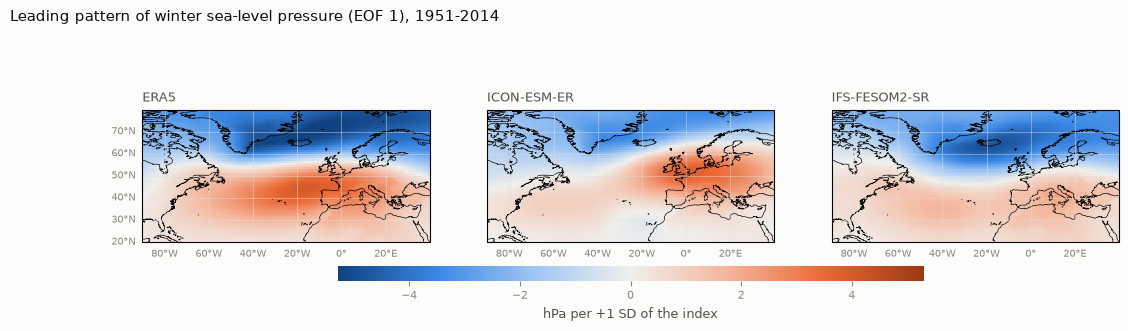

In [3]:
plotting.plot_field_panels({NAME[s]: eofs[s].pattern for s in SOURCES}, units='hPa per +1 SD of the index',
                           title='Leading pattern of winter sea-level pressure (EOF 1), 1951-2014', diverging=True);

**Figure 1.** The NAO pattern in each source. A realistic NAO has a blue centre near Iceland and
southern Greenland and an orange band from the Azores towards Europe, with the zero line between
them around 50–55°N.

**What this cell does.** Puts the patterns into numbers: how much of the winter-to-winter variance
the NAO explains, how separate it is from the second pattern, where its two centres sit and how
strong they are, and how closely each model pattern matches ERA5's (pattern correlation, 1 = same).
The `±` column is the sampling uncertainty of the explained variance (North et al. 1982): if the
first and second patterns overlap within it, they are not cleanly separated.

In [4]:
rows = []
for s in SOURCES:
    e = eofs[s]
    spacing = nao.north_spacing(e.explained, n)
    rows.append({'source': NAME[s],
                 'EOF1 variance %': 100 * e.explained[0], '± %': 100 * spacing[0],
                 'EOF2 variance %': 100 * e.explained[1],
                 'separated from EOF2': bool(e.explained[0] - spacing[0] > e.explained[1] + spacing[1]),
                 **nao.centres(e.pattern),
                 'pattern correlation with ERA5': clim.pattern_stats(e.pattern, eofs['era5'].pattern)['pattern correlation']})
pattern_table = pd.DataFrame(rows)
pattern_table

,source,EOF1 variance %,± %,EOF2 variance %,separated from EOF2,north lat,north lon,north hPa,south lat,south lon,south hPa,pattern correlation with ERA5
0,ERA5,47.38,8.38,17.00,True,71.38,-10.62,-5.44,44.38,-15.62,4.04,1.00
1,ICON-ESM-ER,29.17,5.16,20.72,False,67.38,-31.62,-3.54,51.38,2.38,3.81,0.75
2,IFS-FESOM2-SR,34.78,6.15,23.54,True,63.38,-19.62,-4.90,41.38,12.38,2.14,0.87


**What this cell does.** Subtracts the ERA5 pattern from each model pattern, to show where a
model's NAO is displaced or too weak.

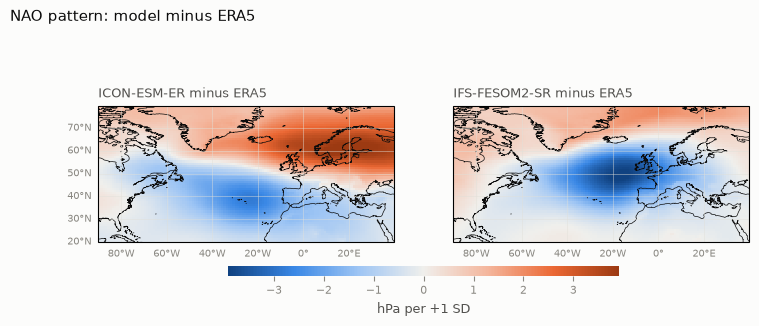

In [5]:
plotting.plot_field_panels({f'{NAME[m]} minus ERA5': eofs[m].pattern - eofs['era5'].pattern for m in MODELS},
                           units='hPa per +1 SD', title='NAO pattern: model minus ERA5', diverging=True);

**Figure 2.** Difference between each model's NAO pattern and ERA5's. Both patterns are per one
standard deviation of their own index, so this also shows if a model's NAO swings are weaker.

## 4. The NAO index

**What this cell does.** Plots the NAO index of every winter, one panel per source. Each index is
in units of its own standard deviation.

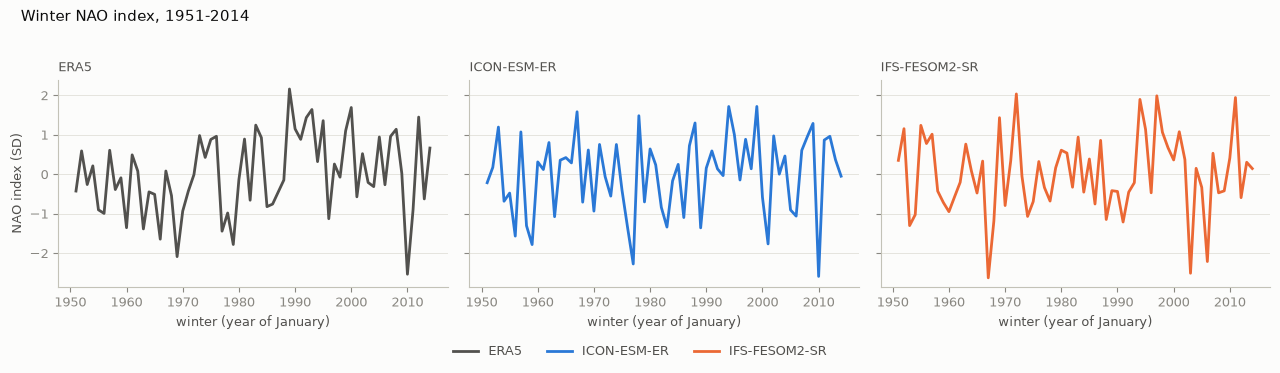

In [6]:
index_panels = {NAME[s]: {s: (eofs[s].index.year.values, eofs[s].index.values)} for s in SOURCES}
plotting.plot_line_panels(index_panels, ylabel='NAO index (SD)', xlabel='winter (year of January)',
                          title='Winter NAO index, 1951-2014', sharey=True);

**Figure 3.** The NAO index. The ERA5 panel is the real history. The model panels are each model's
own history and should not line up with ERA5 winter by winter.

**What this cell does.** A sanity check of the method against well-known winters. It lists the five
most positive and five most negative NAO winters in ERA5, and prints the index for a few winters
that are well known in the literature: strongly positive 1989 and 1995, strongly negative 1963,
1969 and 2010.

In [7]:
era5_index = eofs['era5'].index.to_series()
print('well-known winters:', {int(y): round(float(era5_index[y]), 2) for y in (1963, 1969, 1989, 1995, 2010)})
pd.DataFrame({'most positive winters': era5_index.nlargest(5).index.values,
              'index (SD)': era5_index.nlargest(5).values,
              'most negative winters': era5_index.nsmallest(5).index.values,
              'index (SD) ': era5_index.nsmallest(5).values})

well-known winters: {1963: -1.38, 1969: -2.09, 1989: 2.16, 1995: 1.36, 2010: -2.53}


,most positive winters,index (SD),most negative winters,index (SD)
0,1989,2.16,2010,-2.53
1,2000,1.69,1969,-2.09
2,1993,1.64,1979,-1.78
3,2012,1.45,1966,-1.64
4,1992,1.44,1977,-1.44


## 5. Cross-checks: a station-style index and a common pattern

Two independent checks that the EOF index really is the NAO, and a fairer way to compare strength.

**What this cell does.** Computes the classic station-style NAO, which needs no EOF at all:
normalised pressure near the Azores minus normalised pressure near Iceland (nearest grid points to
38°N 25°W and 65°N 20°W). It then correlates that with the EOF index. A high correlation means the
leading EOF is the NAO and not some other pattern.

In [8]:
station = {s: nao.station_index(winters[s]) for s in SOURCES}
pd.DataFrame([{'source': NAME[s],
               'correlation of EOF index with station-style index': float(np.corrcoef(eofs[s].index, station[s])[0, 1])}
              for s in SOURCES])

,source,correlation of EOF index with station-style index
0,ERA5,0.92
1,ICON-ESM-ER,0.46
2,IFS-FESOM2-SR,0.85


**What this cell does.** Compares the models with ERA5 on a common basis. Each model's winter maps
are projected onto the **ERA5** pattern. That answers two separate questions: (1) is the model's own
leading pattern the same mode as ERA5's NAO (correlation of the two model series), and (2) how
strongly does the model swing along the real NAO pattern (amplitude relative to ERA5, 1.00 = same).

In [9]:
rows = []
for s in SOURCES:
    projected = nao.project(winters[s], eofs['era5'].vector)
    rows.append({'source': NAME[s],
                 'own-pattern amplitude / ERA5': eofs[s].amplitude / eofs['era5'].amplitude,
                 'amplitude along the ERA5 pattern / ERA5': float(projected.std(ddof=1)) / eofs['era5'].amplitude,
                 'correlation: own index vs index on ERA5 pattern': float(np.corrcoef(eofs[s].index, projected)[0, 1])})
common = pd.DataFrame(rows)
projected_index = {s: nao.project(winters[s], eofs['era5'].vector) / eofs['era5'].amplitude for s in SOURCES}
common

,source,own-pattern amplitude / ERA5,amplitude along the ERA5 pattern / ERA5,correlation: own index vs index on ERA5 pattern
0,ERA5,1.00,1.00,1.00
1,ICON-ESM-ER,0.65,0.59,0.83
2,IFS-FESOM2-SR,0.76,0.71,0.91


**What this cell does.** Checks whether a model spreads the real NAO over more than one of its own
patterns. It measures how much of the ERA5 NAO pattern each of a model's first three EOFs contains
(1 = identical pattern, 0 = unrelated). If the second EOF also has a large share, the model's
leading EOF is a mixture and is not a clean NAO.

In [10]:
rows = []
for m in MODELS:
    shares = [nao.overlap(v, eofs['era5'].vector) for v in nao.mode_vectors(winters[m], 3)]
    rows.append({'model': NAME[m], 'EOF1 overlap with ERA5 NAO': shares[0], 'EOF2 overlap': shares[1], 'EOF3 overlap': shares[2]})
pd.DataFrame(rows)

,model,EOF1 overlap with ERA5 NAO,EOF2 overlap,EOF3 overlap
0,ICON-ESM-ER,0.76,0.58,0.04
1,IFS-FESOM2-SR,0.85,0.41,0.23


**How to read this.** An amplitude ratio below 1 means the model's NAO swings are weaker than
observed. With 64 winters, the sampling uncertainty of a standard deviation is roughly ±9%
(one standard error), and a ratio of two of them about ±13%. Ratios between about 0.75 and 1.25
are therefore not clearly different from 1.

## 6. Behaviour in time: persistence and trend

**What this cell does.** Measures two properties of each index: its memory from one winter to the
next (lag-1 autocorrelation; near 0 means each winter is almost independent) and its linear trend
over 1951–2014 with a 95% confidence interval.

In [11]:
rows = []
for s in SOURCES:
    series = eofs[s].index
    t = nao.trend(series.year.values, series.values)
    rows.append({'source': NAME[s], 'lag-1 autocorrelation': nao.autocorrelation(series.values, 1),
                 'trend (SD per decade)': t['trend per decade'], '95% low': t['low'], '95% high': t['high'], 'p value': t['p value']})
print('95% range of lag-1 autocorrelation for', n, 'independent winters: about ±', round(1.96 / np.sqrt(n), 2))
pd.DataFrame(rows)

95% range of lag-1 autocorrelation for 64 independent winters: about ± 0.24


,source,lag-1 autocorrelation,trend (SD per decade),95% low,95% high,p value
0,ERA5,0.22,0.13,0.00,0.27,0.05
1,ICON-ESM-ER,-0.15,0.07,-0.07,0.20,0.33
2,IFS-FESOM2-SR,0.04,0.03,-0.11,0.17,0.65


**What this cell does.** Plots the autocorrelation at lags of 1 to 10 winters, to see if any source
has slow, multi-year swings in its NAO.

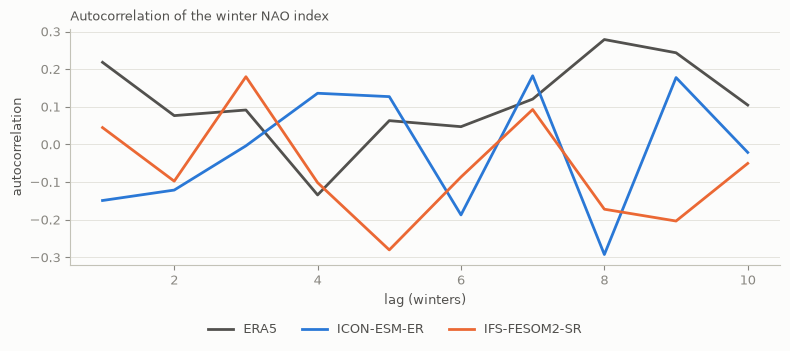

In [12]:
lags = list(range(1, 11))
plotting.plot_line_panels({'Autocorrelation of the winter NAO index': {s: (lags, [nao.autocorrelation(eofs[s].index.values, k) for k in lags]) for s in SOURCES}},
                          ylabel='autocorrelation', xlabel='lag (winters)', columns=1);

**Figure 4.** Autocorrelation of the NAO index. Values inside roughly ±0.25 cannot be told apart
from zero with 64 winters.

## 7. Does the mean-state bias look like the NAO?

Notebook 03 found that ICON-ESM-ER's *average* winter pressure is too low in the north and too
high in the subtropics. That has the same shape as a positive NAO. This section measures it.

**What this cell does.** Takes each model's average winter pressure minus ERA5's (the mean bias,
1951–2014) and projects it onto the ERA5 NAO pattern. The result is expressed in NAO standard
deviations: a value of +2 would mean the model's *average* winter looks like a +2 SD NAO winter
in the real world.

In [13]:
mean_winter = {s: clim.climatology(psl[s], 'DJF') for s in SOURCES}
pd.DataFrame([{'model': NAME[m],
               'mean pressure bias projected on the ERA5 NAO (SD)':
                   nao.project_map(mean_winter[m] - mean_winter['era5'], eofs['era5'].vector) / eofs['era5'].amplitude}
              for m in MODELS])

,model,mean pressure bias projected on the ERA5 NAO (SD)
0,ICON-ESM-ER,2.33
1,IFS-FESOM2-SR,0.51


**Why this matters.** A model can have a realistic NAO *variability* around an unrealistic *mean*.
Extremes depend on the actual flow (mean plus anomaly), so a model that sits permanently in a
positive-NAO-like state may have biased storm-track rainfall even if its NAO index looks fine.

## 8. Does the result depend on the domain?

An EOF depends on the box it is computed in. If ICON-ESM-ER's two leading patterns are mixed only
because of where the box edges lie, a slightly different box should separate them. If they stay
mixed in every box, the mixing is a property of the model's variability. The same test shows
whether the NAO strengths (59% and 71% of ERA5's) depend on the box.

**What this cell does.** Repeats the EOF analysis in five boxes: the standard one and four
variants (smaller in the north, shifted, Atlantic only without Europe, and without the western
Atlantic). In each box it computes ERA5's own NAO pattern, then for every dataset: the variance of
the first two patterns, whether they are separated by the same rule as in section 3 (their
sampling error bars, North et al. 1982, do not overlap), how closely the first pattern resembles
ERA5's in that box, and the NAO strength along ERA5's pattern relative to ERA5.

In [14]:
BOXES = {'standard, 20-80N 90W-40E': (20, 80, -90, 40), '20-70N 90W-40E': (20, 70, -90, 40),
         '25-75N 80W-30E': (25, 75, -80, 30), 'Atlantic only, 20-80N 90W-0E': (20, 80, -90, 0),
         '30-80N 60W-40E': (30, 80, -60, 40)}
rows = []
for box, (south, north, west, east) in BOXES.items():
    sub = {s: winters[s].sel(lat=slice(south, north), lon=slice(west, east)) for s in SOURCES}
    reference = nao.leading_eof(sub['era5'])
    for s in SOURCES:
        e = nao.leading_eof(sub[s])
        spacing = nao.north_spacing(e.explained, sub[s].sizes['year'])
        rows.append({'domain': box, 'dataset': NAME[s], 'EOF1 %': 100 * e.explained[0], 'EOF2 %': 100 * e.explained[1],
                     'separated from EOF2': bool(e.explained[0] - spacing[0] > e.explained[1] + spacing[1]),
                     'pattern correlation with ERA5': clim.pattern_stats(e.pattern, reference.pattern)['pattern correlation'],
                     'NAO strength relative to ERA5': float(nao.project(sub[s], reference.vector).std(ddof=1)) / reference.amplitude})
domains = pd.DataFrame(rows)
domains.pivot(index='domain', columns='dataset')

EOF1 %                           EOF2 %                           separated from EOF2                           pattern correlation with ERA5                            \
dataset                        ERA5 ICON-ESM-ER IFS-FESOM2-SR   ERA5 ICON-ESM-ER IFS-FESOM2-SR                ERA5 ICON-ESM-ER IFS-FESOM2-SR                          ERA5 ICON-ESM-ER IFS-FESOM2-SR   
domain                                                                                                                                                                                                 
20-70N 90W-40E                42.75       28.72         31.88  19.70       22.31         25.88                True       False         False                          1.00        0.29          0.80   
25-75N 80W-30E                47.05       30.15         34.51  19.66       23.80         26.27                True       False         False                          1.00        0.67          0.83   
30-80N 60W-40E                49.19       31.20         36.17  18.97       23.72         25.36                True       False         False                          1.00        0.77          0.87   
Atlantic only, 20-80N 90W-0E  48.78       34.18         39.62  22.78       26.72         28.65                True       False         False                          1.00        0.93          0.63   
standard, 20-80N 90W-40E      47.38       29.17         34.78  17.00       20.72         23.54                True       False          True                          1.00        0.75          0.87   

                             NAO strength relative to ERA5                            
dataset                                               ERA5 ICON-ESM-ER IFS-FESOM2-SR  
domain                                                                                
20-70N 90W-40E                                        1.00        0.56          0.72  
25-75N 80W-30E                                        1.00        0.59          0.70  
30-80N 60W-40E                                        1.00        0.60          0.70  
Atlantic only, 20-80N 90W-0E                          1.00        0.61          0.68  
standard, 20-80N 90W-40E                              1.00        0.59          0.71

**How to read this table.** One row per box; for each dataset the variance of the first two
patterns, whether they are statistically separated, how much the first pattern resembles ERA5's
in the same box, and the NAO strength along ERA5's pattern. A degenerate model shows "False" in
every box and a pattern correlation that jumps around from box to box, because its first pattern
is an arbitrary blend of two modes.

## 9. Saved outputs

**What this cell does.** Saves the winter NAO indices as a small Parquet table in `app_assets/`,
for the NAO-to-extremes notebook and the dashboard. Three versions are kept per source: the index
from the source's own pattern, the index on the common ERA5 pattern, and the station-style index.
A JSON file of the same name records how the table was made: code version (git commit), date,
input datasets with their server versions, and period.

In [15]:
table = pd.concat([pd.DataFrame({'year': eofs[s].index.year.values, 'source': s,
                                 'nao_own_pattern': eofs[s].index.values,
                                 'nao_on_era5_pattern': projected_index[s].values,
                                 'nao_station_style': station[s].values}) for s in SOURCES], ignore_index=True)
out = Path('../app_assets'); out.mkdir(exist_ok=True)
from eerie_uk import provenance
inputs = {s: provenance.dataset_ids(s, 'mon', 'psl', 'north_atlantic') for s in SOURCES}
provenance.write_table(table, out / 'nao_index_winter.parquet', 'Winter (DJF) NAO index per source: own leading EOF, projection on the ERA5 EOF (ERA5 SD units), station-style index', inputs=inputs, period='winters 1951-2014', method='docs/methods.md section 3')
print(len(table), 'rows saved to app_assets/nao_index_winter.parquet')
table.groupby('source')[['nao_own_pattern', 'nao_on_era5_pattern', 'nao_station_style']].agg(['mean', 'std']).round(2)

192 rows saved to app_assets/nao_index_winter.parquet


nao_own_pattern      nao_on_era5_pattern      nao_station_style     
                         mean  std                mean  std              mean  std
source                                                                            
era5                    -0.00 1.00               -0.00 1.00             -0.00 1.00
icon-esm-er              0.00 1.00                0.00 0.59              0.00 1.00
ifs-fesom2-sr           -0.00 1.00               -0.00 0.71              0.00 1.00

## 10. Limitations

- **One member per model, 64 winters.** The NAO is noisy. Differences in strength of 10–20% and in
  explained variance of several percentage points are within sampling uncertainty.
- **ERA5 before about 1979** has fewer observations over the ocean; its early NAO is less certain
  but pressure is one of the best-observed quantities.
- **The pattern depends on the domain and the period.** A different box or different years would
  shift the centres slightly. The same box and years are used for all three sources.
- **Winter means only.** Month-to-month NAO behaviour within a winter is not examined here.
- **Different forcing.** The models follow the HighResMIP `hist-1950` protocol, ERA5 the real world,
  so trends need not agree.
- **The mean-state projection (section 7)** describes the bias; it does not explain its cause.

## 11. Open questions

1. Is the weak NAO of both models a property of the models or of single members? Notebook 07 shows
   that identical atmosphere-only runs give NAO strengths from 0.70 to 1.00 of ERA5's.
2. Section 8 shows that a different box does not separate ICON-ESM-ER's leading patterns. Would
   a longer period, or more members, do so? Upper-air data (jet position) would show what the
   second mode is physically.
3. Does ICON-ESM-ER's positive-NAO-like mean state alter how its extremes respond to the NAO?
   Notebook 06 addresses this.